In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')
%cd /content/drive/MyDrive/Colab_AI 영상처리

Mounted at /content/drive
/content/drive/MyDrive/Colab_AI 영상처리


In [19]:
Image_Path = Path('picture/beagle.jpg')
assert Image_Path.exists(), '이미지 존재X'

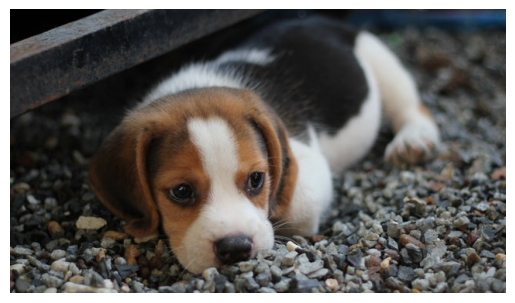

In [20]:
image = cv2.imread(str(Image_Path))       # cv2 :: BGR 방식으로 처리
if image is None :
  raise FileNotFoundError('이미지 없음')

image_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)
plt.imshow(image_rgb)       # plt :: RGB 방식으로 처리
plt.axis('off')
plt.show()

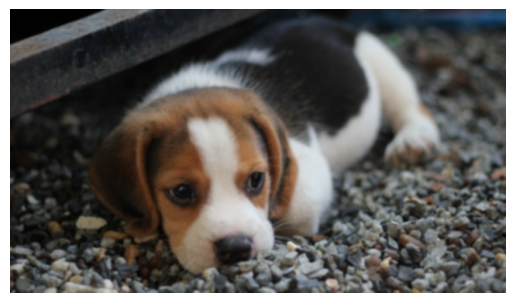

In [23]:
# GaussianBlur() :: 이미지 블러 처리
# 불필요한 정보에 흐릿하게 하여 효율적인 이미지 연산 유도

# (이미지, (n, m), 표준편차)
#     => "n*m 단위의 사각형끼리 경계를 흐트린다"
blur_image = cv2.GaussianBlur(image_rgb, (5, 5), 0)
plt.imshow(blur_image)
plt.axis('off')
plt.show()

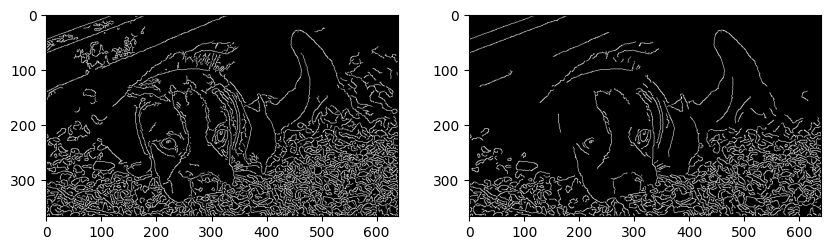

In [27]:
# Canny() :: 경계선 검출 알고리즘
#    (사전작업) 블러 처리 + 흑백 처리
gray_image = cv2.cvtColor(
    blur_image,
    cv2.COLOR_RGB2GRAY
)

# (이미지, 하한선, 상한선)
canny_image = cv2.Canny(gray_image, 10, 70)
canny_image2 = cv2.Canny(gray_image, 70, 120)   # 경계선 기준 엄격
#  픽셀값 70 미만 :: 경계선 취급X
#  픽셀값 120 초과 :: 경계선 확실하게 취급O
#  픽셀값 70~120 :: 주변의 값에 따라 경계선 판단

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(canny_image, cmap='gray')
plt.subplot(1, 2, 2)
plt.imshow(canny_image2, cmap='gray')
plt.show()

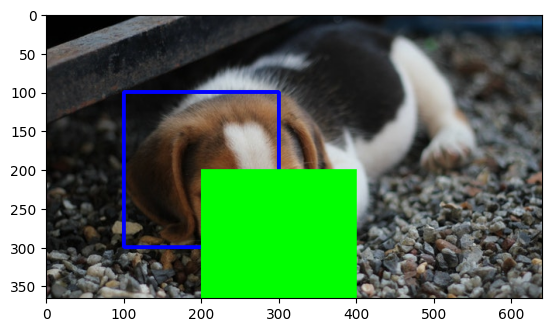

In [29]:
# rectangle() :: 이미지 위에 사각형 그리기

# 원본 훼손 안 되게끔 -> 복사본 만들기
copy_image = image_rgb.copy()

# (이미지, 사각형_시작점, 사각형_종료점, 색상RGB값, 테두리_굵기)
cv2.rectangle(copy_image, (100, 100), (300, 300), (0, 0, 255), 3)
# (200, 200) ~ (400, 400) 초록색 사각형 그리기 (테두리값 -1)
cv2.rectangle(copy_image, (200, 200), (400, 400), (0, 255, 0), -1)    # 사각형 내부 채우기

plt.imshow(copy_image)
plt.show()